In [1]:
!pip install pandas numpy matplotlib seaborn openpyxl

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
uploaded = files.upload()

file_name = next(iter(uploaded))
print("Uploaded file:", file_name)

Saving sample_student_performance.csv to sample_student_performance.csv
Uploaded file: sample_student_performance.csv


In [4]:
if file_name.endswith(".csv"):
    df = pd.read_csv(file_name)
elif file_name.endswith((".xlsx", ".xls")):
    df = pd.read_excel(file_name)
else:
    raise ValueError("Upload a CSV or Excel file")

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,Student_ID,Age,Gender,Department,Study_Hours_Per_Day,Attendance_Percent,Assignment_Score,Exam_Score,Internet_Access,Final_Result
0,1001,19,Female,AIDS,3.5,88,82,85,Yes,Pass
1,1002,20,Male,CSE,2.0,72,68,70,Yes,Pass
2,1003,18,Female,IT,5.0,95,91,94,Yes,Pass
3,1004,21,Male,AIDS,1.5,60,55,58,No,Pass
4,1005,20,Female,ECE,4.0,90,86,88,Yes,Pass


In [5]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset shape: (20, 10)

Column names:
['Student_ID', 'Age', 'Gender', 'Department', 'Study_Hours_Per_Day', 'Attendance_Percent', 'Assignment_Score', 'Exam_Score', 'Internet_Access', 'Final_Result']

Data types:
Student_ID               int64
Age                      int64
Gender                  object
Department              object
Study_Hours_Per_Day    float64
Attendance_Percent       int64
Assignment_Score         int64
Exam_Score               int64
Internet_Access         object
Final_Result            object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Student_ID           20 non-null     int64  
 1   Age                  20 non-null     int64  
 2   Gender               20 non-null     object 
 3   Department           20 non-null     object 
 4   Study_Hours_Per_Day  20 non-null  

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Student_ID,20.0,NaN,NaN,NaN,1010.5,5.91608,1001.0,1005.75,1010.5,1015.25,1020.0
Age,20.0,NaN,NaN,NaN,20.0,1.521772,18.0,19.0,20.0,21.0,23.0
Gender,20,2,Female,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Department,20,5,AIDS,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Study_Hours_Per_Day,20.0,NaN,NaN,NaN,3.3,1.665438,1.0,2.0,3.25,4.5,6.5
Attendance_Percent,20.0,NaN,NaN,NaN,80.2,14.18895,55.0,69.5,85.0,91.25,98.0
Assignment_Score,20.0,NaN,NaN,NaN,76.25,15.860826,48.0,64.5,81.0,89.25,98.0
Exam_Score,20.0,NaN,NaN,NaN,78.45,15.226276,52.0,66.5,83.0,91.25,99.0
Internet_Access,20,2,Yes,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Final_Result,20,2,Pass,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
missing = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (
        missing / len(df) * 100
    ).round(2)
})

display(missing_report)

,Missing_Count,Missing_Percentage
Student_ID,0,0.0
Age,0,0.0
Gender,0,0.0
Department,0,0.0
Study_Hours_Per_Day,0,0.0
Attendance_Percent,0,0.0
Assignment_Score,0,0.0
Exam_Score,0,0.0
Internet_Access,0,0.0
Final_Result,0,0.0


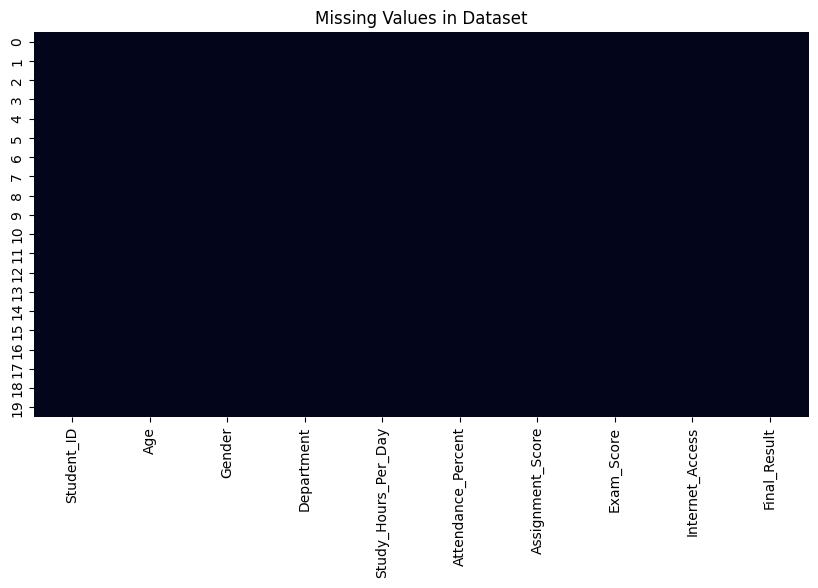

In [7]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values in Dataset")
plt.show()

In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [9]:
df_clean = df.copy()

numeric_cols = df_clean.select_dtypes(
    include=np.number
).columns

categorical_cols = df_clean.select_dtypes(
    include=["object", "category", "string"]
).columns

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

for col in categorical_cols:
    if df_clean[col].notna().any():
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].mode().iloc[0]
        )

print("Remaining missing values:")
print(df_clean.isnull().sum())

Remaining missing values:
Student_ID             0
Age                    0
Gender                 0
Department             0
Study_Hours_Per_Day    0
Attendance_Percent     0
Assignment_Score       0
Exam_Score             0
Internet_Access        0
Final_Result           0
dtype: int64


In [10]:
numeric_cols = df_clean.select_dtypes(
    include=np.number
).columns.tolist()

print("Numerical columns:", numeric_cols)

Numerical columns: ['Student_ID', 'Age', 'Study_Hours_Per_Day', 'Attendance_Percent', 'Assignment_Score', 'Exam_Score']


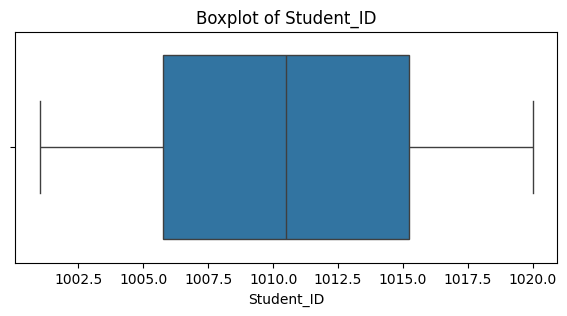

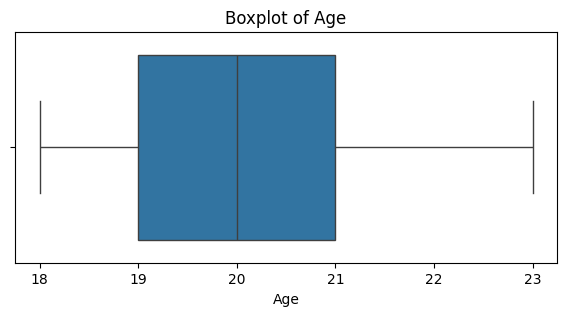

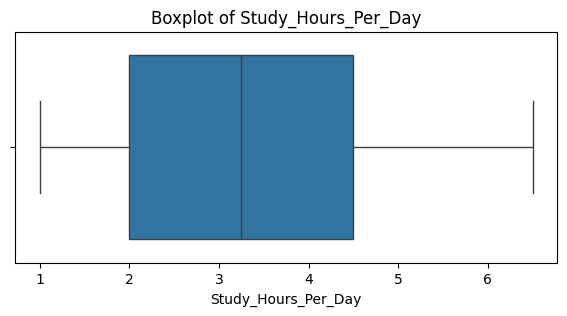

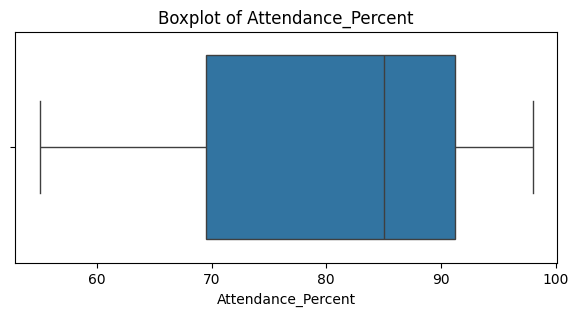

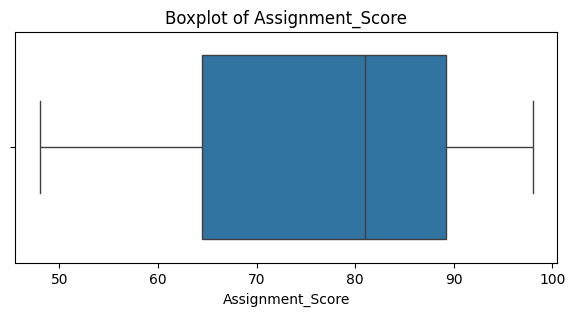

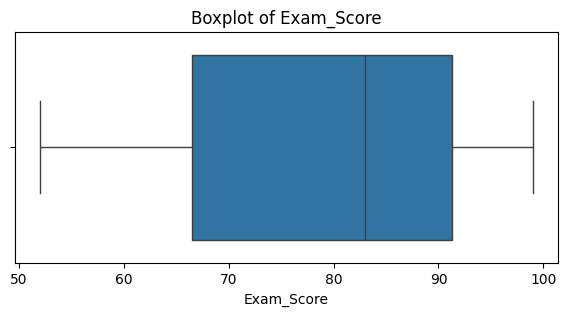

In [11]:
for col in numeric_cols:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df_clean[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [12]:
categorical_cols = df_clean.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

for col in categorical_cols:
    print(f"\nTop categories in {col}:")
    display(df_clean[col].value_counts().head(10))


Top categories in Gender:


,count
Gender,
Female,11
Male,9



Top categories in Department:


,count
Department,
AIDS,5
CSE,4
IT,4
ECE,4
MECH,3



Top categories in Internet_Access:


,count
Internet_Access,
Yes,15
No,5



Top categories in Final_Result:


,count
Final_Result,
Pass,18
Fail,2


In [13]:
outlier_report = []

for col in numeric_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = (
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ).sum()

    outlier_report.append({
        "Column": col,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Potential_Outliers": count
    })

display(pd.DataFrame(outlier_report))

,Column,Lower_Bound,Upper_Bound,Potential_Outliers
0,Student_ID,991.500,1029.500,0
1,Age,16.000,24.000,0
2,Study_Hours_Per_Day,-1.750,8.250,0
3,Attendance_Percent,36.875,123.875,0
4,Assignment_Score,27.375,126.375,0
5,Exam_Score,29.375,128.375,0


In [14]:
summary = {
    "rows": int(df_clean.shape[0]),
    "columns": int(df_clean.shape[1]),
    "column_names": df_clean.columns.tolist(),
    "data_types": df_clean.dtypes.astype(str).to_dict(),
    "missing_values": (
        df_clean.isnull().sum().to_dict()
    ),
    "statistics": (
        df_clean.describe().round(2).to_dict()
    )
}

print(summary)

{'rows': 20, 'columns': 10, 'column_names': ['Student_ID', 'Age', 'Gender', 'Department', 'Study_Hours_Per_Day', 'Attendance_Percent', 'Assignment_Score', 'Exam_Score', 'Internet_Access', 'Final_Result'], 'data_types': {'Student_ID': 'int64', 'Age': 'int64', 'Gender': 'object', 'Department': 'object', 'Study_Hours_Per_Day': 'float64', 'Attendance_Percent': 'int64', 'Assignment_Score': 'int64', 'Exam_Score': 'int64', 'Internet_Access': 'object', 'Final_Result': 'object'}, 'missing_values': {'Student_ID': 0, 'Age': 0, 'Gender': 0, 'Department': 0, 'Study_Hours_Per_Day': 0, 'Attendance_Percent': 0, 'Assignment_Score': 0, 'Exam_Score': 0, 'Internet_Access': 0, 'Final_Result': 0}, 'statistics': {'Student_ID': {'count': 20.0, 'mean': 1010.5, 'std': 5.92, 'min': 1001.0, '25%': 1005.75, '50%': 1010.5, '75%': 1015.25, 'max': 1020.0}, 'Age': {'count': 20.0, 'mean': 20.0, 'std': 1.52, 'min': 18.0, '25%': 19.0, '50%': 20.0, '75%': 21.0, 'max': 23.0}, 'Study_Hours_Per_Day': {'count': 20.0, 'mean': 

In [16]:
report = f"""
AI-ASSISTED EXPLORATORY DATA ANALYSIS

Dataset Overview
----------------
Rows: {df_clean.shape[0]}
Columns: {df_clean.shape[1]}

Column Names
------------
{df_clean.columns.tolist()}

Missing Values
--------------
{df_clean.isnull().sum().to_string()}

Duplicate Rows
--------------
{df_clean.duplicated().sum()}

Numerical Summary
-----------------
{df_clean.describe().round(2).to_string()}

Conclusion
----------
The dataset has been inspected, cleaned where appropriate,
and analyzed using statistical summaries and visualizations.
AI-assisted interpretation can help explain patterns,
potential anomalies and areas for further investigation.
"""

with open("EDA_Report.txt", "w", encoding="utf-8") as f:
    f.write(report)

print(report)


AI-ASSISTED EXPLORATORY DATA ANALYSIS

Dataset Overview
----------------
Rows: 20
Columns: 10

Column Names
------------
['Student_ID', 'Age', 'Gender', 'Department', 'Study_Hours_Per_Day', 'Attendance_Percent', 'Assignment_Score', 'Exam_Score', 'Internet_Access', 'Final_Result']

Missing Values
--------------
Student_ID             0
Age                    0
Gender                 0
Department             0
Study_Hours_Per_Day    0
Attendance_Percent     0
Assignment_Score       0
Exam_Score             0
Internet_Access        0
Final_Result           0

Duplicate Rows
--------------
0

Numerical Summary
-----------------
       Student_ID    Age  Study_Hours_Per_Day  Attendance_Percent  Assignment_Score  Exam_Score
count       20.00  20.00                20.00               20.00             20.00       20.00
mean      1010.50  20.00                 3.30               80.20             76.25       78.45
std          5.92   1.52                 1.67               14.19             1

In [17]:
df_clean.to_csv("Cleaned_Dataset.csv", index=False)

print("Files generated successfully!")

Files generated successfully!


In [19]:
files.download("Cleaned_Dataset.csv")
files.download("EDA_Report.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>